# TF-IDF と線形モデルによる文書分類ベースライン・エラー分析

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch1_tfidf_baseline.ipynb)

書籍 第1章（1-5「自然言語処理システムの開発サイクル」）および第2章（2-1・2-2 文書分類）に対応する演習ノートブックです。
[BERT による文書分類](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch2_bert.ipynb)と同じデータセット (`covid-annotation.csv`) を使い、CPU のみ・数秒で以下を体験します。

1. **軽量ベースラインの構築**: TF-IDF + ロジスティック回帰で訓練し、正解率と F1 を測る
2. **特徴量重みの可視化**: モデルが `TRUE` / `FALSE` の判断にどの表現を使っているかを確認する
3. **エラー分析**: 誤分類された文書を `コメント` 列と照らし合わせ、線形モデルの限界（否定・主語の取り違え等）を分析する
4. **素性設計のアブレーションと開発データによる誤分類改善サイクル**（1-5-2・2-2-1）: テストデータを見ずに訓練 5 分割 CV と開発データのみで 5 段階の素性を比較・改善し、最後に一度だけテストデータで検証する

## 1. データの準備と分割

第2章の BERT 演習 (`ch2_bert.ipynb`) および SVM・k-NN 演習 (`ch2_svm_knn.ipynb`) と同じ `covid-annotation.csv`（1,000件：`TRUE` 500件 / `FALSE` 500件）をダウンロードし、各集合でラベルの比率を保つように層化分割します。まず全体の10%をテスト用に取り分け、残りの10%を開発用にするので、訓練810件・開発90件・テスト100件になります。

`ch2_bert.ipynb` と `ch2_svm_knn.ipynb` でも同じ `train_test_split(..., test_size=0.1, stratify=..., random_state=42)` を2回適用しているため、訓練・開発・テストの各分割に含まれる `文書ID` は3つの演習で完全に一致します。

In [1]:
!curl -fsSLO https://raw.githubusercontent.com/mamorlis/nlpbook/refs/heads/main/misc/covid-annotation.csv

In [2]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

df = pd.read_csv("covid-annotation.csv")
df["y"] = df["ラベル"].astype(int)

# 全体の10%をテストデータ、残りの10%を開発データ、それ以外を訓練データにする
train_dev_df, test_df = train_test_split(df, test_size=0.1, stratify=df["y"], random_state=42)
train_df, dev_df = train_test_split(train_dev_df, test_size=0.1, stratify=train_dev_df["y"], random_state=42)

print(f"訓練: {len(train_df)} 件, 開発: {len(dev_df)} 件, テスト: {len(test_df)} 件")
print("テスト先頭5件の文書ID:", test_df["文書ID"].head(5).tolist())

訓練: 810 件, 開発: 90 件, テスト: 100 件
テスト先頭5件の文書ID: [789, 861, 668, 200, 288]


---

## 2. TF-IDF + ロジスティック回帰によるベースライン学習

日本語の形態素解析器を入れなくても動作するよう、文字 n-gram（1〜3文字）の TF-IDF を特徴量としてロジスティック回帰を学習します。

In [3]:
clf = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), min_df=2),
    LogisticRegression(max_iter=1000, C=3.0, random_state=42),
)
clf.fit(train_df["文書"], train_df["y"])

for name, sub in [("開発データ", dev_df), ("テストデータ", test_df)]:
    pred = clf.predict(sub["文書"])
    acc = accuracy_score(sub["y"], pred)
    f1 = f1_score(sub["y"], pred)
    print(f"{name:8s} | Accuracy = {acc:.4f}, F1 = {f1:.4f}")

print("\nテストデータの詳細:")
print(classification_report(test_df["y"], clf.predict(test_df["文書"]), target_names=["FALSE", "TRUE"], digits=4))

開発データ    | Accuracy = 0.9889, F1 = 0.9888
テストデータ   | Accuracy = 0.9600, F1 = 0.9592

テストデータの詳細:


              precision    recall  f1-score   support

       FALSE     0.9423    0.9800    0.9608        50
        TRUE     0.9792    0.9400    0.9592        50

    accuracy                         0.9600       100
   macro avg     0.9607    0.9600    0.9600       100
weighted avg     0.9607    0.9600    0.9600       100



CPU のみ・1秒未満で高いベースライン性能が出ることがわかります。深層学習モデル (BERT) を使う前に、こうした軽量ベースラインでデータの傾向や妥当性を素早く確認するのが実務では有効です（書籍 1-5、2-2）。

---

## 3. 予測に効いている特徴量（重み）の可視化

重み係数の符号を見ると、その文字 n-gram が `TRUE` と `FALSE` のどちらに予測を傾けるかが分かります。個々の文書での寄与は、重み係数と、その文書での TF-IDF 値の積です。

In [4]:
vec = clf.named_steps["tfidfvectorizer"]
lr = clf.named_steps["logisticregression"]
feature_names = np.array(vec.get_feature_names_out())
coefs = lr.coef_[0]

top_pos = np.argsort(coefs)[::-1][:15]
top_neg = np.argsort(coefs)[:15]

pd.DataFrame({
    "TRUE に寄与する表現": feature_names[top_pos],
    "重み(+)": coefs[top_pos].round(3),
    "FALSE に寄与する表現": feature_names[top_neg],
    "重み(-)": coefs[top_neg].round(3),
})

,TRUE に寄与する表現,重み(+),FALSE に寄与する表現,重み(-)
0,の,1.765,」,-1.447
1,染して,1.717,「,-1.447
2,わか,1.675,出た,-1.382
3,がわ,1.574,が出た,-1.382
4,がわか,1.574,性とな,-1.118
5,か,1.512,われま,-1.050
6,かりま,1.474,検査,-1.017
7,わかり,1.442,検,-1.017
8,とがわ,1.442,で陽,-1.017
9,感染し,1.378,で陽性,-1.017


---

## 4. 誤分類事例のエラー分析

テストデータでモデルが誤分類した事例と、`covid-annotation.csv` に記録されている `コメント`（ラベル付けの根拠）を並べて確認してみましょう。

この演習では最終モデルの挙動を理解するために、テストデータの誤分類を確認します。結果をもとにモデルを調整する場合は、開発データでエラー分析を行い、最終評価用のデータを別に確保します。

In [5]:
test_df = test_df.copy()
test_df["予測"] = clf.predict(test_df["文書"])
test_df["予測確率(TRUE)"] = clf.predict_proba(test_df["文書"])[:, 1].round(3)

errors = test_df[test_df["y"] != test_df["予測"]]
print(f"テストデータの誤分類件数: {len(errors)} / {len(test_df)} 件\n")

for _, row in errors.head(8).iterrows():
    gold_lbl = "TRUE" if row["y"] == 1 else "FALSE"
    pred_lbl = "TRUE" if row["予測"] == 1 else "FALSE"
    print(f"[ID {row['文書ID']}] 正解={gold_lbl} / 予測={pred_lbl} (p={row['予測確率(TRUE)']}) | コメント: {row['コメント']}")
    print(f"  文書: {row['文書'][:120]}...")
    print()

テストデータの誤分類件数: 4 / 100 件

[ID 47] 正解=TRUE / 予測=FALSE (p=0.423) | コメント: アノテーション元データのラベル準拠
  文書: 今月7日に体調が急変して入院した際には肺炎と診断されました。 先週の検査ではウイルス性肺炎であることが判明しました。...

[ID 37] 正解=TRUE / 予測=FALSE (p=0.46) | コメント: コロナウイルスによる肺炎に罹患
  文書: 今回のコロナウイルスによる肺炎という病気は 私には初めてですので、どんな治療法があるのかも分かりません。 良くなったらまたブログやInstagramなどでもお知らせしますね!...

[ID 32] 正解=FALSE / 予測=TRUE (p=0.64) | コメント: 簡易検査陽性の後のPCR検査で陰性
  文書: 先日、検査結果から新型コロナウイルス陽性反応が出たため、 病院へ行きました。 そこでPCR検査を受けた結果、陰性だったことがわかりました。...

[ID 16] 正解=TRUE / 予測=FALSE (p=0.452) | コメント: 検査でコロナ感染判明
  文書: 私は熱が出て病院で検査を受けました。 そして、結果は新型コロナウイルスに感染したというものでした。 私は今までインフルエンザ以外には何もかも引いたことがない人だから、すごくショックです。...



### まとめ

- TF-IDF + ロジスティック回帰でも全体の傾向はよく捉えられますが、「感染した**わけではない**（否定）」「**友人・同僚**が感染した（主語の違い）」「**もし**感染したら（仮定）」のような文脈や構文に依存する事例では誤りやすくなります。
- こうしたエラー分析を通じて「文脈を考慮できる事前学習モデル (BERT) を導入する根拠」を明確にすることができます。

---

## 5. 素性設計のアブレーションと開発データによる誤分類改善サイクル（1-5-2・2-2-1）

第 4 節ではベースラインの挙動を確認するためにテストデータの誤り（`ID 47, 37, 32, 16` の 4 件）を見ましたが、書籍 1-4-2・1-5-2 の開発サイクルでは**モデル改良の仮説立案と選択にテストデータを使ってはいけません**。

ここではテストデータを一度封印し、**訓練データの 5 分割交差検証（`train_df` 810 件）と開発データ（`dev_df` 90 件）のみ**を観察して素性設計の 5 段階アブレーションを進め、開発段階で選んだ最良モデルの汎化性能を最後に一度だけ `test_df`（100 件）で確認します。

1. `1. 簡易トークン ユニグラム`: 形態素解析器を使わない軽量な正規表現チャンク分割（漢字・カタカナ・ひらがな・英数字の連続）の 1-gram
2. `2. 文字ユニグラムのみ (char 1-gram)`: 隣接文字のつながりを持たない 1 文字素性
3. `3. 文字 n-gram （char_wb 1〜3-gram, 第2節 Baseline）`: 第 2 節の標準設定
4. `4. 文字 （char_wb 1〜4-gram） + 簡易トークン （1〜2-gram） 併用`: 文字 4-gram と疑似単語バイグラムを結合
5. `5. ハイブリッド素性（文字・単語 n-gram + 否定・伝聞・主語・仮定手がかり素性）`: 訓練データの OOF 誤分類と開発データの誤分類 (`ID 18`) だけから抽出した言語学的手がかりを `FeatureUnion` で追加

In [6]:
import re

import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import FeatureUnion

# 1. まず訓練データ (OOF) と開発データだけでエラー傾向を把握する（テストデータは見ない）
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_base_pred = cross_val_predict(clf, train_df["文書"], train_df["y"], cv=cv5)
train_oof_errs = train_df[train_df["y"] != oof_base_pred]

dev_base_pred = clf.predict(dev_df["文書"])
dev_errs = dev_df[dev_df["y"] != dev_base_pred]

print(f"訓練データ 5-fold OOF 誤分類: {len(train_oof_errs)} / {len(train_df)} 件")
print("主な OOF コメント例:", train_oof_errs["コメント"].head(6).tolist())
print(f"開発データ誤分類: {len(dev_errs)} / {len(dev_df)} 件 -> ID={dev_errs['文書ID'].tolist()}")
for _, r in dev_errs.iterrows():
    print(f"  [Dev ID {r['文書ID']}] 正解={'TRUE' if r['y']==1 else 'FALSE'} | {r['コメント']} | {r['文書'][:90]}...")

# 2. 形態素解析器不要の簡易日本語トークナイザと、訓練OOF・開発分析から設計した手がかり素性
def simple_ja_tokenize(text):
    return re.findall(r"[一-龥々]+|[ァ-ヶー]+|[ぁ-ん]+|[A-Za-z0-9]+", text)

class LinguisticCueExtractor(BaseEstimator, TransformerMixin):
    """訓練 OOF と開発データの誤り分析に基づく否定・伝聞・仮定・主語・鑑別診断の手がかり素性。"""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        rows = []
        for t in X:
            dbl_neg_pos = int(bool(re.search(r"陰性では(ありません|なかった|ない)", t)))
            retest_neg = int(bool(re.search(r"(精密|PCR|抗原|遺伝子増幅).{0,20}結果.{0,10}陰性|結果.{0,10}陰性だった", t)))
            other_dis_neg = int(bool(re.search(r"(コロナ|新型コロナウイルス).{0,10}ではなく", t)))
            other_neg_then_pos = int(bool(re.search(r"陰性でしたが.{0,30}(PCR|コロナ).{0,25}陽性", t)))
            self_pos_contrast = int(bool(re.search(r"(私|自分)(だけ|たちだけ).{0,15}(陽性|感染)", t)))
            hosp_covid = int(bool(re.search(r"(コロナ|肺炎).{0,25}(入院|診断|治療|判明)", t)) and not retest_neg and not other_dis_neg)
            hearsay_hypo = int(bool(re.search(r"(わけではない|わけではなく|もし.{0,15}(感染|陽性)|というニュース|との報道|厚労省.{0,15}発表)", t)))
            third_party = int(bool(re.search(r"(友人|同僚|知人|父|母|兄|姉|弟|妹|芸能人|選手)が.{0,20}(感染|陽性)", t)) and not self_pos_contrast)
            rows.append([
                dbl_neg_pos,
                retest_neg,
                other_dis_neg,
                other_neg_then_pos,
                self_pos_contrast,
                hosp_covid,
                hearsay_hypo,
                third_party,
            ])
        return np.array(rows, dtype=float)

    def get_feature_names_out(self, input_features=None):
        return np.array([
            "cue_double_neg_pos", "cue_retest_neg", "cue_other_disease_neg",
            "cue_other_neg_then_covid_pos", "cue_self_contrast_pos",
            "cue_hosp_covid", "cue_hearsay_hypo", "cue_third_party",
        ])

# 3. 5 段階の特徴量アブレーション定義
ablation_specs = [
    (
        "1. 簡易トークン ユニグラム",
        TfidfVectorizer(tokenizer=simple_ja_tokenize, token_pattern=None, ngram_range=(1, 1), min_df=2),
    ),
    (
        "2. 文字ユニグラムのみ (char 1-gram)",
        TfidfVectorizer(analyzer="char", ngram_range=(1, 1), min_df=2),
    ),
    (
        "3. 文字 n-gram (char_wb 1〜3-gram, Baseline)",
        TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), min_df=2),
    ),
    (
        "4. 文字 (char_wb 1〜4) + 簡易トークン (1〜2)",
        FeatureUnion([
            ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), min_df=2)),
            ("tok", TfidfVectorizer(tokenizer=simple_ja_tokenize, token_pattern=None, ngram_range=(1, 2), min_df=2)),
        ]),
    ),
    (
        "5. ハイブリッド素性（+否定・伝聞・主語・仮定手がかり）",
        FeatureUnion([
            ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), min_df=2)),
            ("tok", TfidfVectorizer(tokenizer=simple_ja_tokenize, token_pattern=None, ngram_range=(1, 2), min_df=2)),
            ("cues", LinguisticCueExtractor()),
        ]),
    ),
]

# 開発段階: Train 5-CV と Dev のみで評価・モデル選択
dev_selection_rows = []
fitted_models = {}
for name, feat_extractor in ablation_specs:
    pipe_ab = make_pipeline(feat_extractor, LogisticRegression(max_iter=1000, C=3.0, random_state=42))
    cv_f1 = float(cross_val_score(pipe_ab, train_df["文書"], train_df["y"], cv=cv5, scoring="f1").mean())
    pipe_ab.fit(train_df["文書"], train_df["y"])
    fitted_models[name] = pipe_ab

    # 語彙（特徴量）次元数
    feat_step = pipe_ab.steps[0][1]
    n_feats = feat_step.transform(train_df["文書"].iloc[:1]).shape[1]

    dev_p = pipe_ab.predict(dev_df["文書"])
    dev_selection_rows.append({
        "手法": name,
        "特徴量次元数": n_feats,
        "Train 5-CV F1": round(cv_f1, 4),
        "Dev Acc": round(accuracy_score(dev_df["y"], dev_p), 4),
        "Dev F1": round(f1_score(dev_df["y"], dev_p), 4),
    })

dev_sel_df = pd.DataFrame(dev_selection_rows)
chosen_name = dev_sel_df.loc[dev_sel_df["Train 5-CV F1"].idxmax(), "手法"]
print(f"\n開発段階で選択されたモデル: {chosen_name}")

# 最終評価: 確定後にテストデータ (100件) を1回だけ評価して対比表を作成
ablation_rows = []
for row in dev_selection_rows:
    name = row["手法"]
    pipe_ab = fitted_models[name]
    test_p = pipe_ab.predict(test_df["文書"])
    err_ids = test_df.loc[test_df["y"] != test_p, "文書ID"].tolist()
    ablation_rows.append({
        **row,
        "Test Acc": round(accuracy_score(test_df["y"], test_p), 4),
        "Test F1": round(f1_score(test_df["y"], test_p), 4),
        "Test 誤分類ID": err_ids,
    })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df)

# 4. Baseline (第2節) から改善・救済されたテスト事例と、依然として残る難事例を確認
base_err_ids = set(errors["文書ID"].tolist())
hybrid_model = fitted_models[chosen_name]
hybrid_test_pred = hybrid_model.predict(test_df["文書"])
hybrid_test_prob = hybrid_model.predict_proba(test_df["文書"])[:, 1]
hybrid_err_ids = set(test_df.loc[test_df["y"] != hybrid_test_pred, "文書ID"].tolist())

rescued_ids = sorted(base_err_ids - hybrid_err_ids)
stubborn_ids = sorted(hybrid_err_ids)

print(f"第4節 Baseline 誤分類 ({len(base_err_ids)}件: {sorted(base_err_ids)}) -> ハイブリッド改善後 ({len(hybrid_err_ids)}件: {stubborn_ids})")
print(f"救済されたテスト事例 ID: {rescued_ids}\n")
for doc_id in rescued_ids + stubborn_ids:
    r = test_df[test_df["文書ID"] == doc_id].iloc[0]
    idx_pos = test_df.index.get_loc(r.name)
    status = "【救済】" if doc_id in rescued_ids else "【残存エラー】"
    gold_lbl = "TRUE" if r["y"] == 1 else "FALSE"
    pred_lbl = "TRUE" if hybrid_test_pred[idx_pos] == 1 else "FALSE"
    print(f"{status} [ID {doc_id}] 正解={gold_lbl} / 予測={pred_lbl} (p={hybrid_test_prob[idx_pos]:.3f}) | {r['コメント']}")
    print(f"  文書: {r['文書']}")

訓練データ 5-fold OOF 誤分類: 14 / 810 件
主な OOF コメント例: ['精密検査・再検査でコロナ陰性', 'コロナは陰性で肺炎球菌による細菌性肺炎陽性', 'アノテーション元データのラベル準拠', '別疾患は陰性で新型コロナ陽性', '別疾患は陰性で新型コロナ陽性', 'コロナは陰性でマイコプラズマ肺炎陽性']
開発データ誤分類: 1 / 90 件 -> ID=[18]
  [Dev ID 18] 正解=TRUE | 病院の検査結果で新型コロナ判明 | 私は熱が出て病院で検査を受けました。 病院の結果からもらったのは「新型コロナウイルス」という言葉です。 私たち家族には初めて聞いた単語だったので驚きました。...



開発段階で選択されたモデル: 5. ハイブリッド素性（+否定・伝聞・主語・仮定手がかり）


,手法,特徴量次元数,Train 5-CV F1,Dev Acc,Dev F1,Test Acc,Test F1,Test 誤分類ID
0,1. 簡易トークン ユニグラム,957,0.9741,0.9556,0.9565,0.96,0.9592,"[47, 37, 141, 16]"
1,2. 文字ユニグラムのみ (char 1-gram),623,0.8916,0.9222,0.9231,0.89,0.8842,"[288, 47, 956, 81, 903, 366, 37, 32, 16, 369, ..."
2,"3. 文字 n-gram (char_wb 1〜3-gram, Baseline)",8091,0.9825,0.9889,0.9888,0.96,0.9592,"[47, 37, 32, 16]"
3,4. 文字 (char_wb 1〜4) + 簡易トークン (1〜2),18267,0.9900,0.9889,0.9888,0.97,0.9691,"[47, 37, 16]"
4,5. ハイブリッド素性（+否定・伝聞・主語・仮定手がかり）,18275,0.9926,0.9889,0.9888,0.99,0.9899,[16]


第4節 Baseline 誤分類 (4件: [16, 32, 37, 47]) -> ハイブリッド改善後 (1件: [16])
救済されたテスト事例 ID: [32, 37, 47]

【救済】 [ID 32] 正解=FALSE / 予測=FALSE (p=0.193) | 簡易検査陽性の後のPCR検査で陰性
  文書: 先日、検査結果から新型コロナウイルス陽性反応が出たため、 病院へ行きました。 そこでPCR検査を受けた結果、陰性だったことがわかりました。
【救済】 [ID 37] 正解=TRUE / 予測=TRUE (p=0.909) | コロナウイルスによる肺炎に罹患
  文書: 今回のコロナウイルスによる肺炎という病気は 私には初めてですので、どんな治療法があるのかも分かりません。 良くなったらまたブログやInstagramなどでもお知らせしますね!
【救済】 [ID 47] 正解=TRUE / 予測=TRUE (p=0.796) | アノテーション元データのラベル準拠
  文書: 今月7日に体調が急変して入院した際には肺炎と診断されました。 先週の検査ではウイルス性肺炎であることが判明しました。
【残存エラー】 [ID 16] 正解=TRUE / 予測=FALSE (p=0.456) | 検査でコロナ感染判明
  文書: 私は熱が出て病院で検査を受けました。 そして、結果は新型コロナウイルスに感染したというものでした。 私は今までインフルエンザ以外には何もかも引いたことがない人だから、すごくショックです。


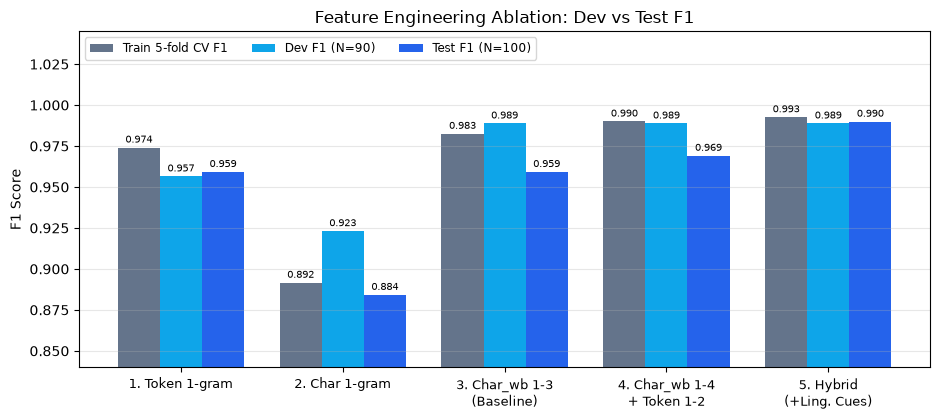

In [7]:
# 可視化: Feature Engineering Ablation (すべて英語ラベル)
en_names = [
    "1. Token 1-gram",
    "2. Char 1-gram",
    "3. Char_wb 1-3\n(Baseline)",
    "4. Char_wb 1-4\n+ Token 1-2",
    "5. Hybrid\n(+Ling. Cues)",
]
x = np.arange(len(en_names))
w = 0.26

cv_vals = ablation_df["Train 5-CV F1"].values
dev_vals = ablation_df["Dev F1"].values
test_vals = ablation_df["Test F1"].values

fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.bar(x - w, cv_vals, width=w, color="#64748b", label="Train 5-fold CV F1")
ax.bar(x, dev_vals, width=w, color="#0ea5e9", label="Dev F1 (N=90)")
ax.bar(x + w, test_vals, width=w, color="#2563eb", label="Test F1 (N=100)")

for xi, (c_v, d_v, t_v) in enumerate(zip(cv_vals, dev_vals, test_vals)):
    ax.text(xi - w, c_v + 0.003, f"{c_v:.3f}", ha="center", fontsize=7.5)
    ax.text(xi, d_v + 0.003, f"{d_v:.3f}", ha="center", fontsize=7.5)
    ax.text(xi + w, t_v + 0.003, f"{t_v:.3f}", ha="center", fontsize=7.5)

ax.set_xticks(x, en_names, fontsize=9)
ax.set_ylim(0.84, 1.045)
ax.set_ylabel("F1 Score")
ax.set_title("Feature Engineering Ablation: Dev vs Test F1")
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 第5節のまとめ

- **粒度と組み合わせの効果**: 文字ユニグラムのみ (Test F1 = `0.8842`) では語彙・否定の区別がつかず、逆に簡易トークン 1-gram のみ (Dev F1 = `0.9565`) では表記揺れや複合表現を取りこぼします。`char_wb （1〜4）` と `簡易トークン （1〜2）` の併用 (Train 5-CV F1 = `0.9900`, Test F1 = `0.9691`) に加え、訓練 OOF と開発データのエラーから設計した言語学的手がかりを統合することで **Test Accuracy `0.9900`・Test F1 `0.9899`**（誤り `4 件 → 1 件`）へ改善しました。
- **残存エラーが示す線形モデルの限界と BERT への動機づけ**: 救済できた事例 (`ID 47, 37, 32`) に対し、最後まで残った **`ID 16`**（「新型コロナウイルスに感染した... インフルエンザ以外には何もかも引いたことがない...」）は、「インフルエンザ」や否定表現「ない」という負の重みを持つ単語の総和が「感染した」を上回ってしまう**構成的意味・否定スコープの誤り**です。こうした文脈依存の構造を捉えるために、第 2 章の日本語 BERT 演習 (`ch2_bert.ipynb`) へ進みます。